# Retail Inventory Analytics — Project 2
The challenge PDF provides the dataset schema and analysis tasks, but the supplied material does not contain row-level data or an explicit prediction label. This implementation therefore uses synthetic data and derives `Fast_Moving` from the 75th percentile of `Units_Sold`.

In [1]:
from pathlib import Path
import pandas as pd
BASE = Path('..')
df = pd.read_csv(BASE/'data/retail_sales_clean.csv', parse_dates=['Date'])
df.head()

,Date,Store_ID,Product_ID,Category,Opening_Stock,Units_Sold,Closing_Stock,Price,Promotion,Holiday,Stock_Out,Inventory_Turnover,Fast_Moving,Historical_Avg_Units_Sold
0,2025-01-02,STORE-06,PROD-001,Beverages,133,27,106,62.69,0,0,0,0.203008,0,28.892500
1,2025-01-03,STORE-01,PROD-001,Snacks,45,7,38,159.09,1,0,0,0.155556,0,27.000000
2,2025-01-06,STORE-03,PROD-001,Dairy,70,30,40,371.20,0,0,0,0.428571,0,17.000000
3,2025-01-07,STORE-02,PROD-001,Personal Care,110,24,86,90.84,0,0,0,0.218182,0,21.333333
4,2025-01-09,STORE-06,PROD-001,Staples,117,12,105,84.71,0,0,0,0.102564,0,22.000000


In [2]:
print(df.describe(include='all').T)
print('\nRows:', len(df))
print('Stock-out rate:', df['Stock_Out'].mean())
print('Average inventory turnover:', df['Inventory_Turnover'].mean())

                            count unique       top freq                 mean  \
Date                         2400    NaN       NaN  NaN  2025-04-30 13:48:00   
Store_ID                     2400      8  STORE-01  328                  NaN   
Product_ID                   2400     30  PROD-011  100                  NaN   
Category                     2400      6   Staples  436                  NaN   
Opening_Stock              2400.0    NaN       NaN  NaN            98.509583   
Units_Sold                 2400.0    NaN       NaN  NaN              28.8925   
Closing_Stock              2400.0    NaN       NaN  NaN            70.811667   
Price                      2400.0    NaN       NaN  NaN           256.217225   
Promotion                  2400.0    NaN       NaN  NaN             0.257083   
Holiday                    2400.0    NaN       NaN  NaN                 0.13   
Stock_Out                  2400.0    NaN       NaN  NaN               0.0875   
Inventory_Turnover         2400.0    NaN

In [3]:
print('Fast-moving threshold:', df['Units_Sold'].quantile(.75))
print('\nSales by category:')
print(df.groupby('Category')['Units_Sold'].sum().sort_values(ascending=False))
print('\nPromotion comparison:')
print(df.groupby('Promotion')['Units_Sold'].mean())
print('\nStock-out rate by store:')
print(df.groupby('Store_ID')['Stock_Out'].mean().sort_values(ascending=False))

Fast-moving threshold: 39.0

Sales by category:
Category
Beverages        13408
Staples          12658
Snacks           12644
Dairy            12164
Personal Care     9723
Household         8745
Name: Units_Sold, dtype: int64

Promotion comparison:
Promotion
0    26.698822
1    35.231767
Name: Units_Sold, dtype: float64

Stock-out rate by store:
Store_ID
STORE-06    0.120141
STORE-08    0.091503
STORE-05    0.090343
STORE-04    0.087413
STORE-01    0.082317
STORE-07    0.078689
STORE-02    0.078498
STORE-03    0.071942
Name: Stock_Out, dtype: float64


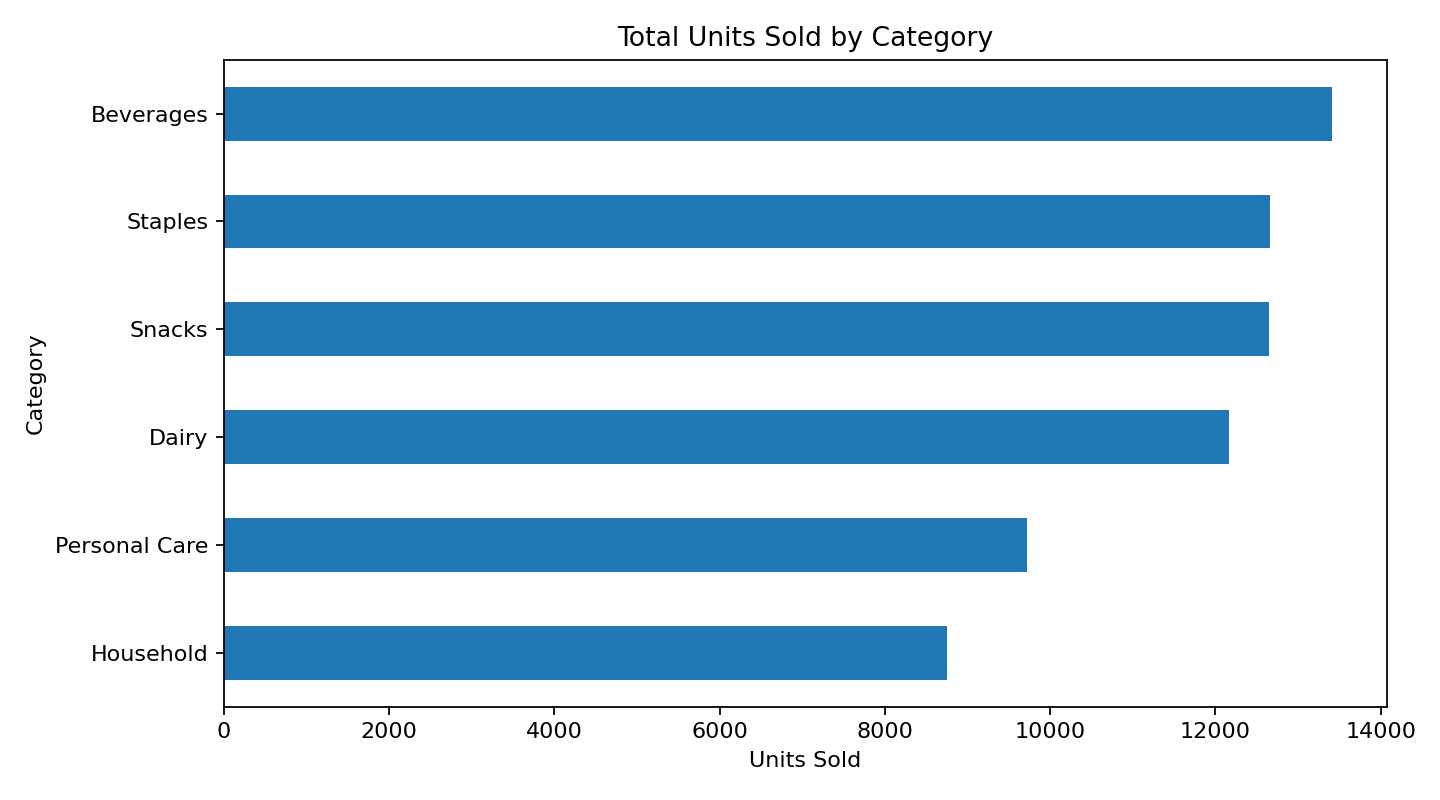

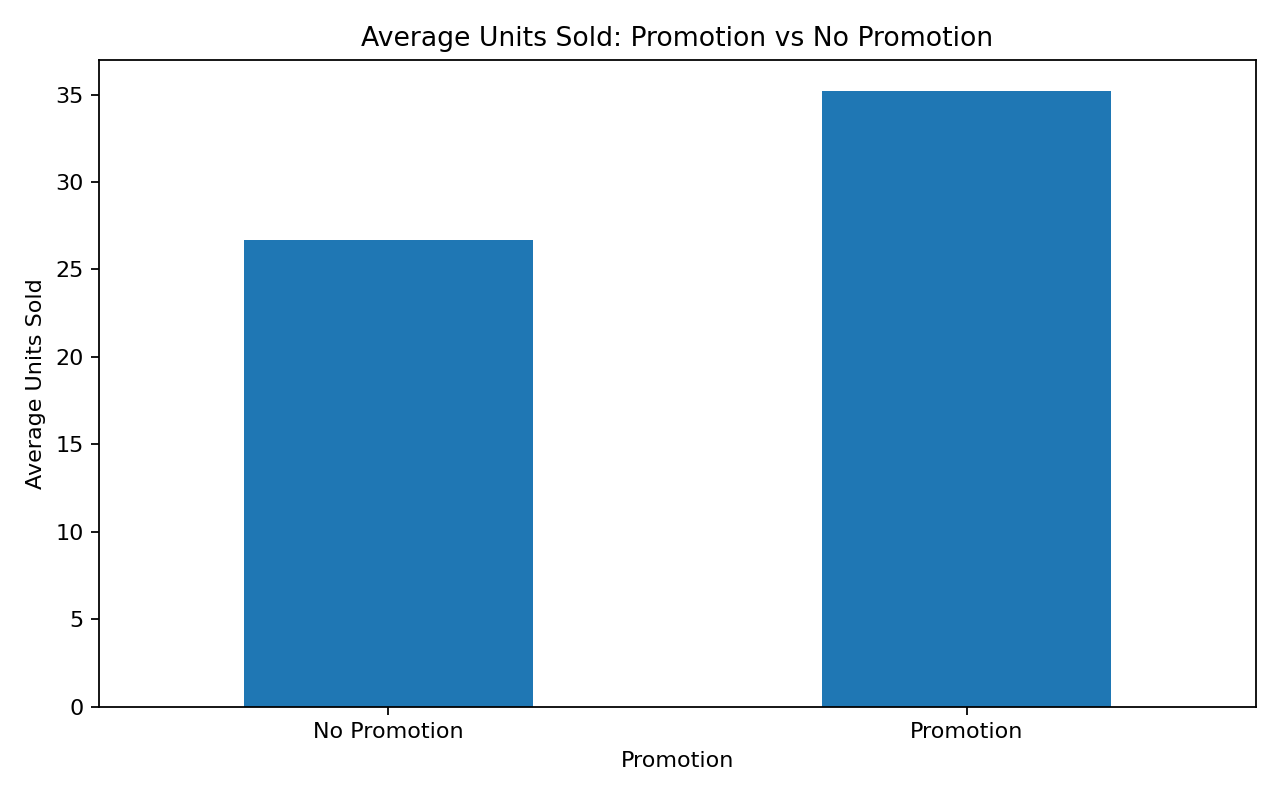

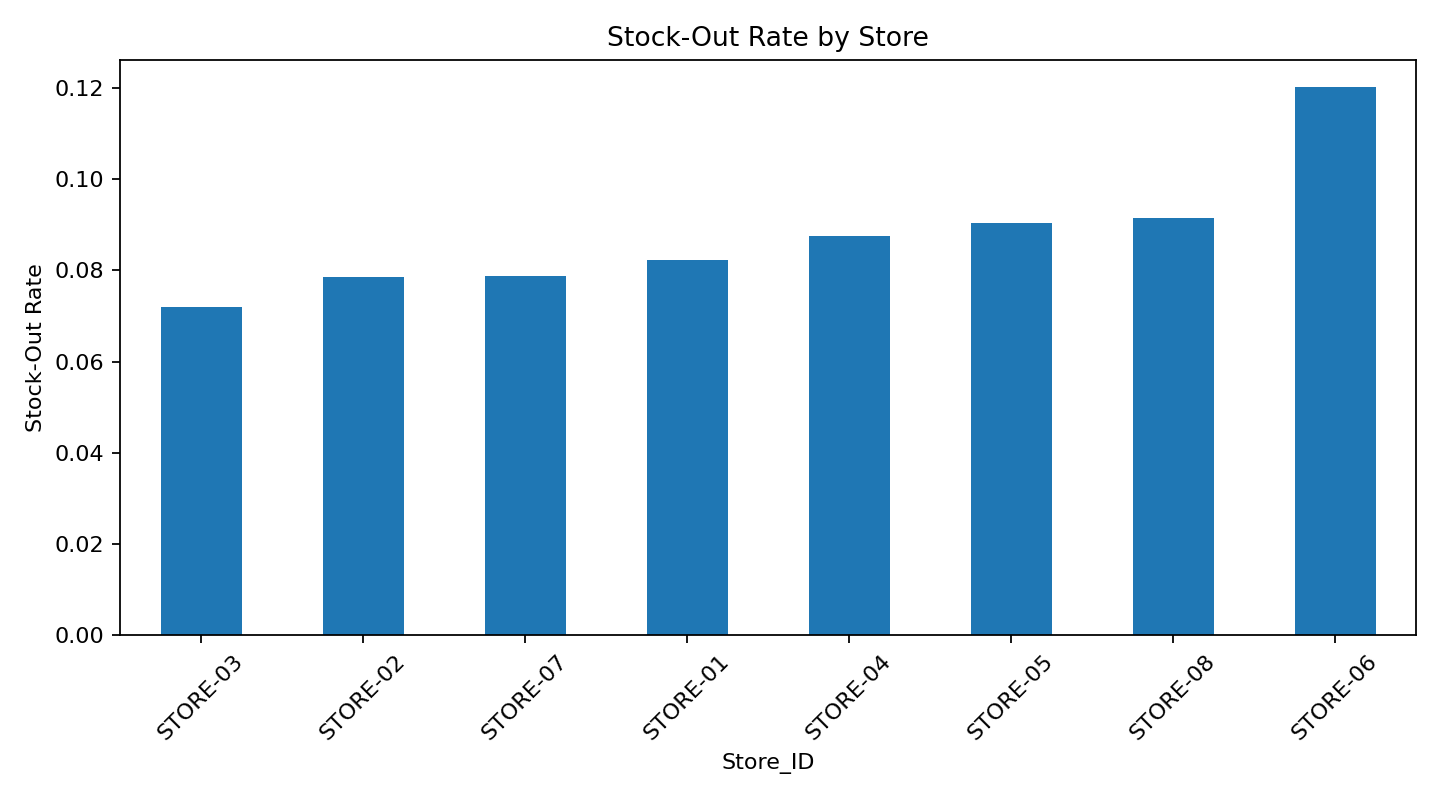

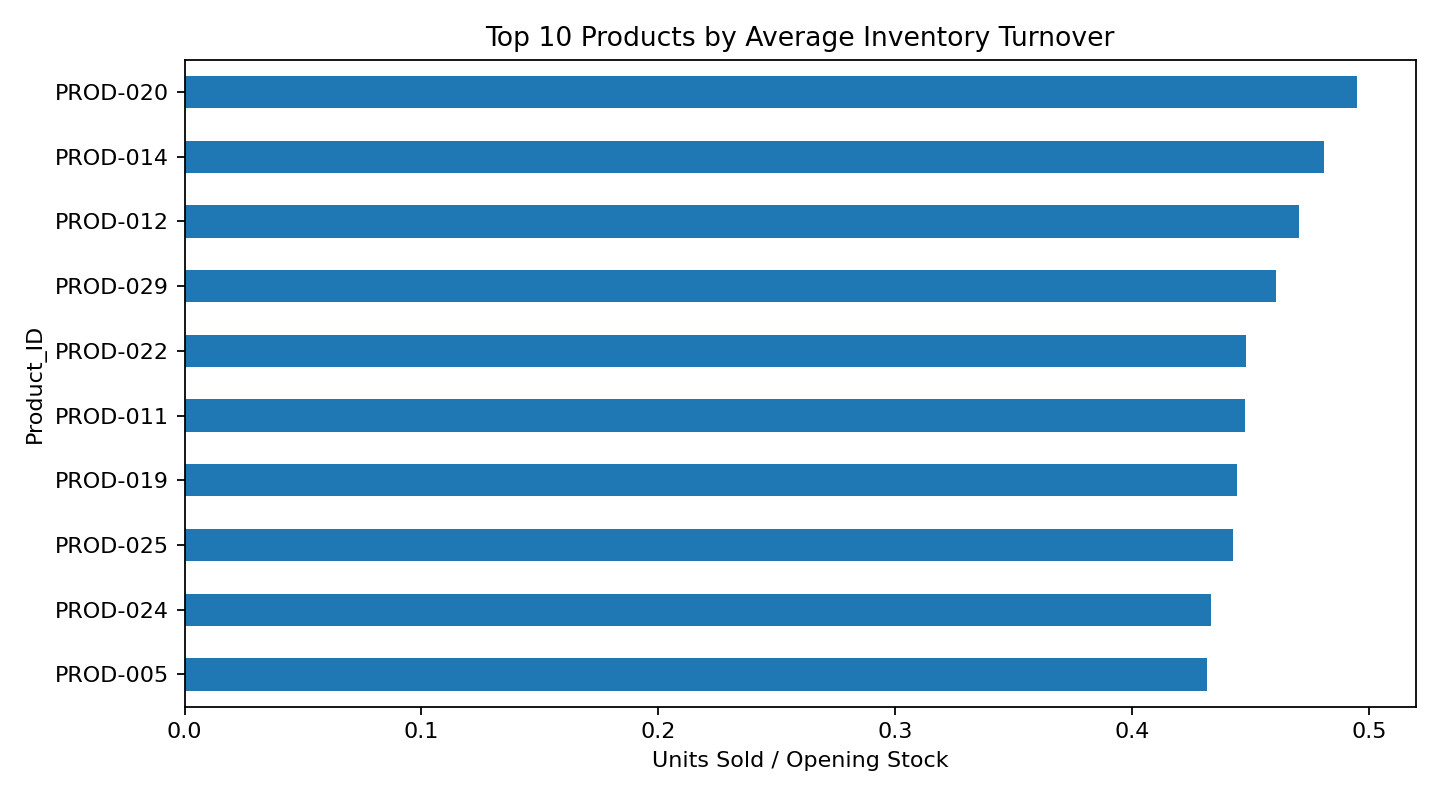

In [4]:
from IPython.display import display
from PIL import Image
for f in sorted((BASE/'visualizations').glob('*.png')):
    display(Image.open(f))

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
features=['Store_ID','Category','Opening_Stock','Price','Promotion','Holiday','Historical_Avg_Units_Sold']
X=df[features]; y=df['Fast_Moving']
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,random_state=42,stratify=y)
pre=ColumnTransformer([('cat',OneHotEncoder(handle_unknown='ignore'),['Store_ID','Category']),('num','passthrough',['Opening_Stock','Price','Promotion','Holiday','Historical_Avg_Units_Sold'])])
model=Pipeline([('preprocess',pre),('rf',RandomForestClassifier(n_estimators=300,random_state=42,class_weight='balanced',min_samples_leaf=2))])
model.fit(Xtr,ytr); pred=model.predict(Xte)
print(classification_report(yte,pred))

              precision    recall  f1-score   support

           0       0.77      0.88      0.82       357
           1       0.41      0.24      0.31       123

    accuracy                           0.72       480
   macro avg       0.59      0.56      0.56       480
weighted avg       0.68      0.72      0.69       480



## Key insights and action plan
1. Category-level sales show which categories drive unit movement.
2. Promotion and non-promotion sales can be compared before allocating additional promotional inventory.
3. Store-level stock-out rates identify locations needing replenishment review.
4. Inventory turnover highlights products that convert stock into sales quickly.
5. High-turnover or high-stock-out products are candidates for higher replenishment levels.
6. Low-turnover and low-stock-out products are candidates for tighter inventory levels.
7. The Random Forest uses prior product demand as a historical signal while excluding the current day's sales from the predictors.

**Target note:** `Fast_Moving` is a derived demonstration target because the challenge PDF does not explicitly define a prediction label.